# Minimum and Maximum Temperature

Projected annual minimum (`tasmin`) and maximum (`tasmax`) near-surface air temperature at the selected site from the CSIRO CMIP6 multi-model ensemble.

```{glue:figure} anomalies_fig
:scale: 60%
:align: right
```

**Figure. Temperature anomalies relative to 2015–2035.** Median across models (lines), 25–75 % and 10–90 % ranges (shading) for mean, minimum and maximum temperature.

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

Import libraries and helper functions. Projection plotting utilities come from the [indicators_setup](https://github.com/lauracagigal/indicators_setup) repository (`ind_setup.plotting_projections`); data access, site configuration and output helpers come from `functions/projections.py` and `functions/site_common.py`.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display
from myst_nb import glue

sys.path.append("../../../../../../indicators_setup")
from ind_setup.plotting_projections import plot_palau_temperature_anomalies_by_scenario, get_box_data, plot_global_warming_boxplot

sys.path.append("../../../../functions")
from site_common import load_site_config, list_available_sites, site_config_filename, build_site_tag, build_site_figures_dir, build_site_tables_dir
import projections as prj

### Define location

Set `site_key` to one of the sites configured with [`../../../historical/National/00_site_setup.ipynb`](../../../historical/National/00_site_setup.ipynb) (see the list printed below). The notebook reads the coordinates and country from `data/sites/<site_key>.json`, exactly as the historical notebooks do.

In [3]:
sites_dir = Path("../../../../data/sites")
available_sites = list_available_sites(sites_dir)
print(f"{len(available_sites)} site(s) already configured in {sites_dir}:")
display(available_sites)

6 site(s) already configured in ../../../../data/sites:


,site_key,site_name,country,ghcn_station_id,ghcn_station_name,vars_interest
0,cook_islands_new_zealand_cwm00091843,cook_islands_new_zealand_CWM00091843,Cook Islands [New Zealand],CWM00091843,RAROTONGA INTL GSN 91843,"[TMIN, TMAX, PRCP]"
1,marshall_islands_rmw00040604,marshall_islands_RMW00040604,Marshall Islands,RMW00040604,MH KWAJALEIN GSN 91366,"[TMIN, TMAX, PRCP]"
2,marshall_islands_rmw00040710,marshall_islands_RMW00040710,Marshall Islands,RMW00040710,MH MAJURO WBAS AP GSN 91376,"[TMIN, TMAX, PRCP]"
3,niue_new_zealand_nem00091824,niue_new_zealand_NEM00091824,Niue [New Zealand],NEM00091824,HANAN AIRPORT GSN 91824,"[TMIN, TMAX, PRCP]"
4,palau,Palau,Palau,None,None,None
5,palau_psw00040309,palau_PSW00040309,Palau,PSW00040309,PW KOROR GSN 91408,"[TMIN, TMAX, PRCP]"


In [4]:
site_key = "palau_psw00040309"  # pick a site_key from the table printed above

site_cfg = load_site_config(sites_dir / site_config_filename(site_key))

site_name = site_cfg.get("site_name", "Site")
site_lon = float(site_cfg["site_lon"])
site_lat = float(site_cfg["site_lat"])
country = site_cfg.get("country", site_name)
site_label = country

site_tag = build_site_tag(site_name, site_lon, site_lat)
fig_dir = build_site_figures_dir(Path("../../../../outputs"), site_name, site_lon, site_lat)
tables_dir = build_site_tables_dir(Path("../../../../outputs"), site_name, site_lon, site_lat)
cache_dir = prj.site_cache_dir(site_tag)
print(f"{country}: lon {site_lon}, lat {site_lat} -> figures in {fig_dir}")

Palau: lon 134.4769, lat 7.3367 -> figures in ../../../../outputs/figures/palau_psw00040309_lat7p337_lon134p477


### Scenarios and global warming levels

Years at which the IPCC AR6 multi-model mean global surface temperature first reaches each warming level (°C above 1850–1900), computed in [`../00_warming_levels.ipynb`](../00_warming_levels.ipynb). Local values are read from every model at those years.

In [5]:
ssp_scenarios = ['ssp126', 'ssp245', 'ssp370', 'ssp585']
incr_temps = list(prj.WARMING_LEVELS)
delta_t = 0  # warming levels are already expressed relative to 1850–1900

scenario_info = prj.load_warming_levels(ssp_scenarios)
pd.DataFrame({sc: {f"+{wl}°C": info["year"] for wl, info in levels.items()} for sc, levels in scenario_info.items()})

,ssp126,ssp245,ssp370,ssp585
+1.5°C,2032-01-01,2030-01-01,2030-01-01,2027-01-01
+2.0°C,NaT,2052-01-01,2046-01-01,2041-01-01
+2.5°C,NaT,2079-01-01,2061-01-01,2053-01-01
+3.0°C,NaT,NaT,2075-01-01,2064-01-01


### Get data

Multi-model CMIP6 projections prepared by CSIRO on a common 1° Pacific grid (one file per scenario and variable, `ensemble_<ssp>_<variable>_commongrid.nc`). The series at the grid cell nearest to the site is cached under `data/projections/<site_tag>/`; delete that file or set `overwrite=True` to extract it again.

In [6]:
ds = xr.merge([prj.extract_point(var, site_lon, site_lat, ssp_scenarios, cache_file=cache_dir / f"{var}_point.nc")
               for var in ["tas", "tasmin", "tasmax"]], join="outer", compat="override", combine_attrs="drop_conflicts")
print(f"Grid cell used: lon {ds.attrs.get('grid_lon')}, lat {ds.attrs.get('grid_lat')}")

Grid cell used: lon 134.0, lat 7.0


## Analysis

### Anomalies by scenario

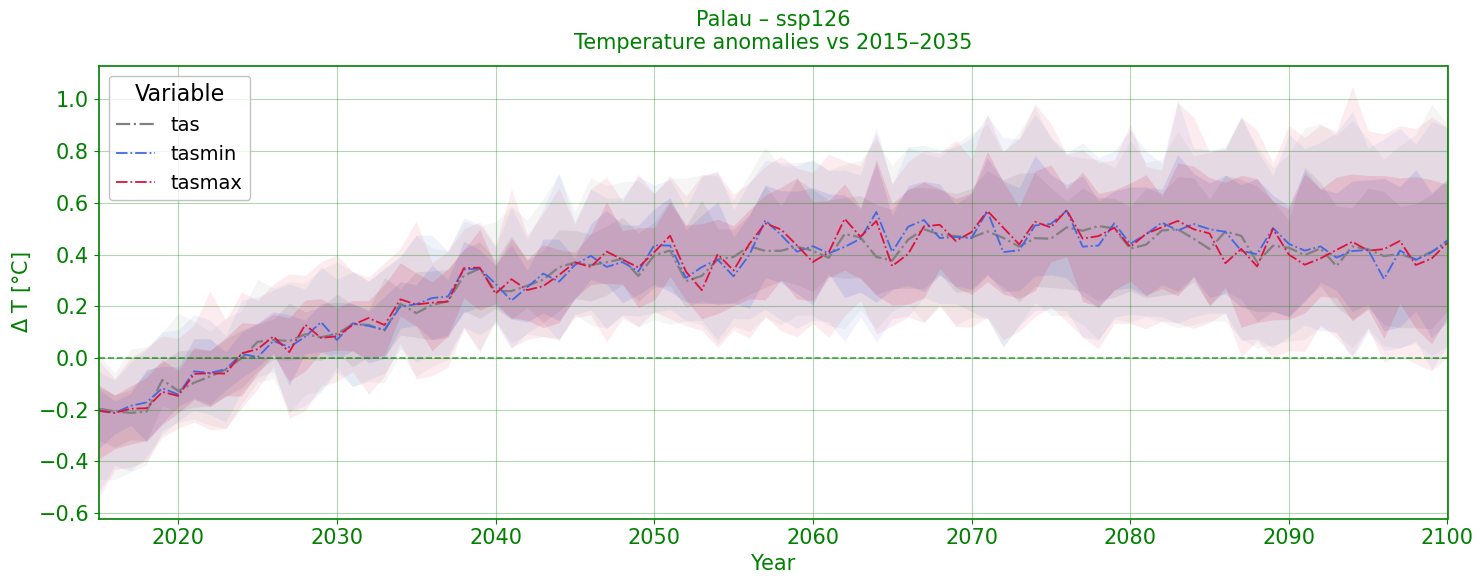

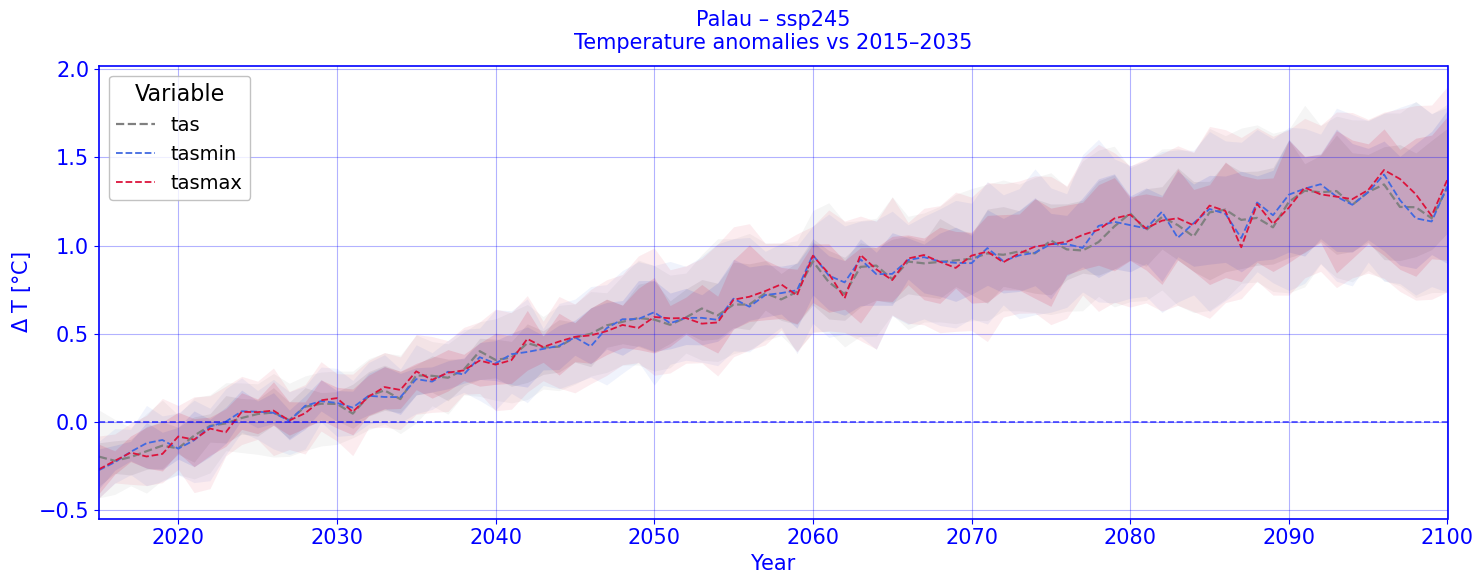

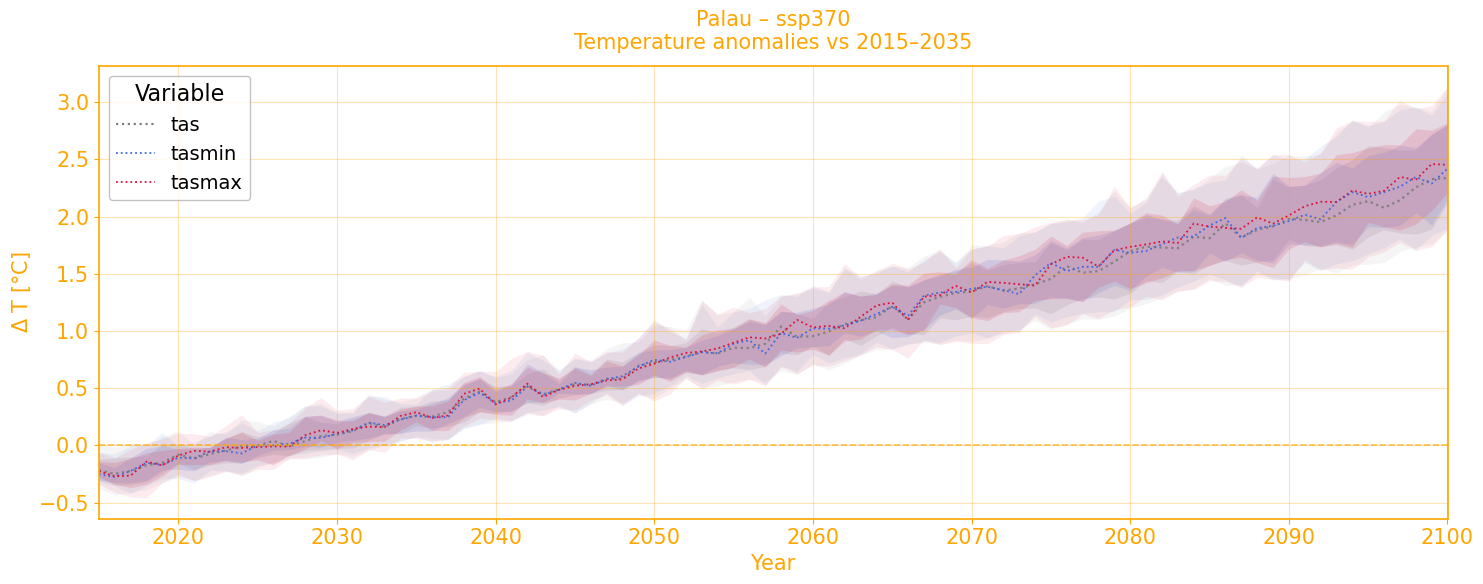

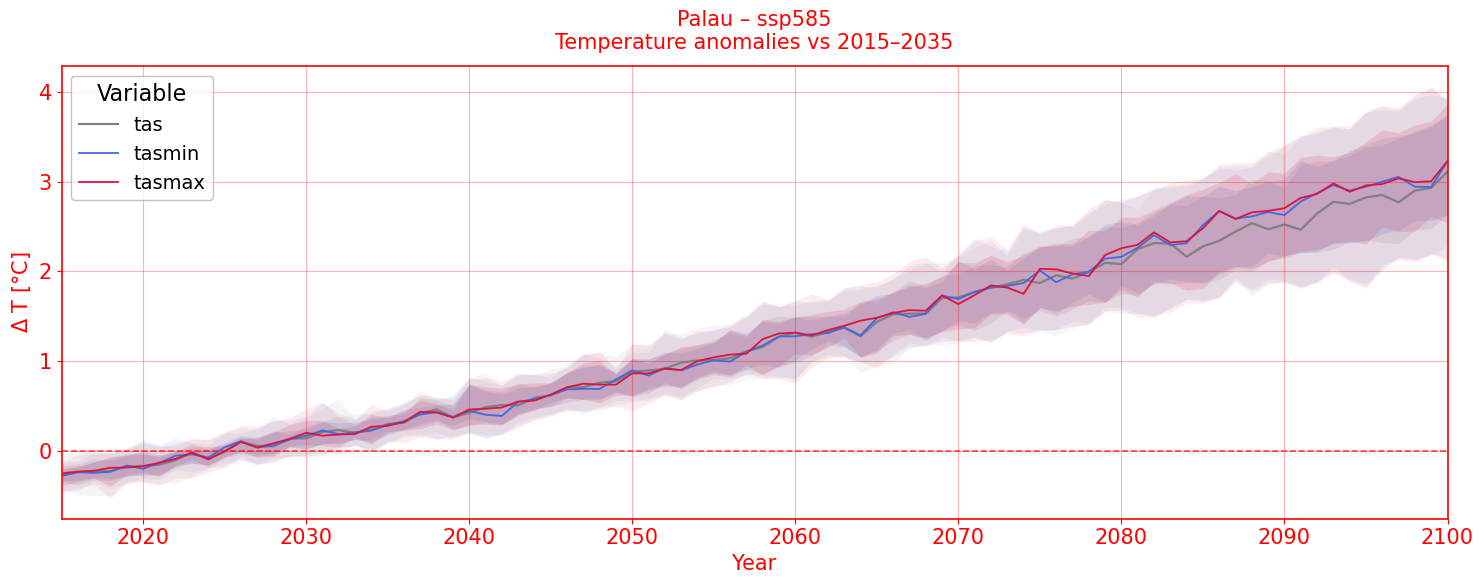

In [7]:
for scenario in ssp_scenarios:
    fig = plot_palau_temperature_anomalies_by_scenario(ds, scenario=scenario, site_label=site_label)
    prj.save_figure(fig, fig_dir, f"air_temp_minmax_{scenario}", site_tag)
    if scenario == "ssp245":
        glue("anomalies_fig", fig, display=False)

### Minimum and maximum temperature at global warming levels

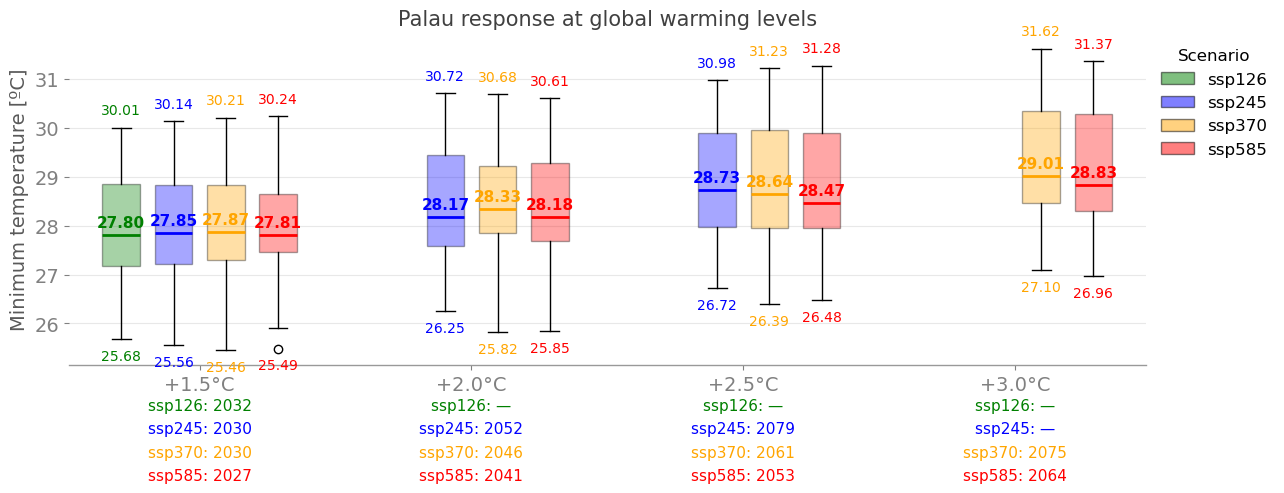

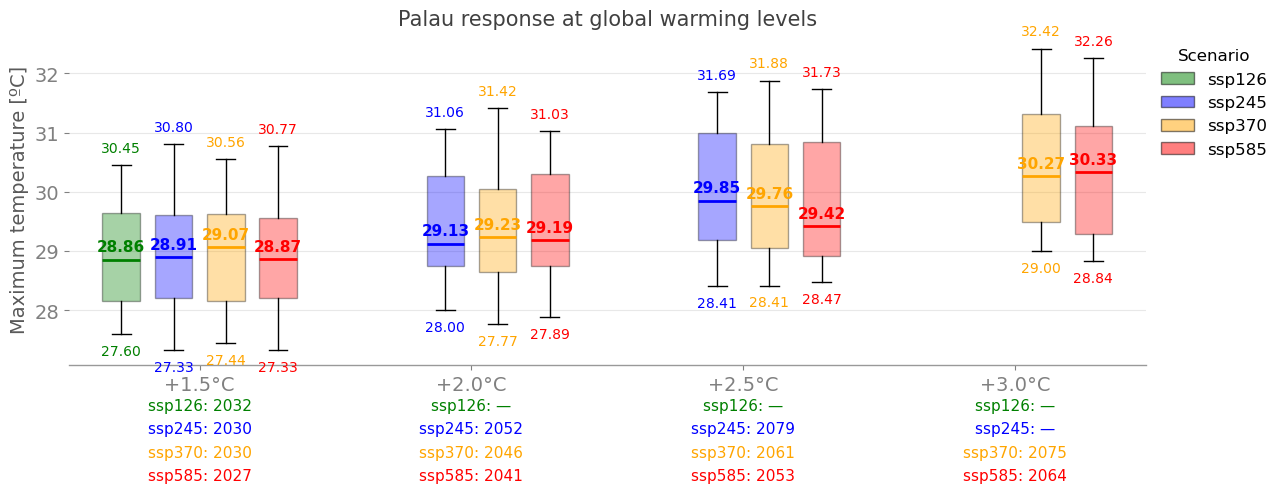

In [8]:
for var, label in [("tasmin", "Minimum temperature [ºC]"), ("tasmax", "Maximum temperature [ºC]")]:
    box_data, box_scenarios, positions = get_box_data(ds, scenario_info, incr_temps, ssp_scenarios, var)
    fig, ax = plot_global_warming_boxplot(box_data, ds, positions, box_scenarios, scenario_info, incr_temps, var,
                                          plot_ref=False, texts=True, delta_t=delta_t, site_label=site_label, ylabel=label)
    prj.save_figure(fig, fig_dir, f"air_temp_{var}_gwl", site_tag)

In [9]:
table = pd.concat([prj.gwl_summary(ds, var, scenario_info, ssp_scenarios, decimals=2).assign(Variable=var)
                   for var in ['tasmin', 'tasmax']], ignore_index=True)
prj.save_table(table, tables_dir, "air_temp_minmax_gwl", site_tag)
table

,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max,Variable
0,SSP126,+1.5°C,2032,27,27.80,26.23,29.35,25.68,30.01,tasmin
1,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN,tasmin
2,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN,tasmin
3,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN,tasmin
4,SSP245,+1.5°C,2030,27,27.85,26.29,29.36,25.56,30.14,tasmin
5,SSP245,+2.0°C,2052,27,28.17,26.80,29.99,26.25,30.72,tasmin
6,SSP245,+2.5°C,2079,27,28.73,27.50,30.50,26.72,30.98,tasmin
7,SSP245,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN,tasmin
8,SSP370,+1.5°C,2030,27,27.87,26.40,29.26,25.46,30.21,tasmin
9,SSP370,+2.0°C,2046,27,28.33,26.80,29.53,25.82,30.68,tasmin
